# Model check: the bypass models against the routing tables and ns-3

Does the bypass cost throughput where the models in `docs/bypass-modelling.tex` say it should?

1. **Flow-level check** (`05-bypass-model`): oversubscription under random permutations as the small flows' share of bytes, *f*, grows, measured on our routing tables with ECMP's even split and with the best split (the LP), next to both models.
2. **ns-3 under permutation traffic** (`06-permutation`): large-flow throughput with each bypass, relative to no bypass, by the kind of pair, and whether the pairs the flow-level check says are most loaded are the slow ones in ns-3.

Reads the batch that has the sweep set by `SWEEP` (normally `06-permutation`), and the flow-level check in the same batch. It shows whatever runs have finished.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common

common.setup_plots()
pd.options.display.float_format = "{:,.3f}".format

print(f"Reading {common.MACHINE}/{common.BATCH}")
oversubscription, pair_loads = common.load_model_checks()
scales = sorted(set(zip(oversubscription["nodes"], oversubscription["degree"]))) if len(oversubscription) else []
print(f"Flow-level check: {oversubscription[['nodes', 'degree', 'seed']].drop_duplicates().shape[0] if scales else 0} runs at scales {scales}")

Reading remote/2026-11-13_102950_bcb7193
Flow-level check: 6 runs at scales [(256, 16), (1000, 64)]


## 1. Flow-level check

Each row averages over permutations. `ecmp_kept` and `lp_kept` are the throughput every pair keeps relative to no bypass: oversubscription without the bypass over oversubscription with it, per permutation. The model columns are Model 3 of the guide:

- **ECMP model:** *O*(1 − *f*) + *f d* / *c*, with *O* each permutation's measured oversubscription without the bypass and *c* its weakest bypassed pair's shortest paths (Step 7).
- **Ideal model:** max(1/Σμ, *f d* / *c*) (Step 6).

`lp_worst` is the worst permutation's LP oversubscription. Above the ideal model, single-path pairs share a link.

In [2]:
checks = pd.DataFrame()
if scales:
    checks = oversubscription.copy()
    checks["lp_r"] = (checks["lp_lower"] + checks["lp_upper"]) / 2
    keys = ["nodes", "degree", "seed", "matching"]
    baseline = checks[checks["mode"] == "none"].set_index(keys)[["ecmp_r", "lp_r", "model_ideal"]].add_suffix("_none")
    checks = checks[checks["mode"] != "none"].join(baseline, on=keys)
    checks["ecmp_kept"] = checks["ecmp_r_none"] / checks["ecmp_r"]
    checks["lp_kept"] = checks["lp_r_none"] / checks["lp_r"]
    checks["model_ecmp_kept"] = checks["ecmp_r_none"] / (
        checks["ecmp_r_none"] * (1 - checks["share"]) + checks["share"] * checks["degree"] / checks["min_c"]
    )
    checks["model_ideal_kept"] = checks["model_ideal_none"] / checks["model_ideal"]
    display(
        checks.groupby(["nodes", "degree", "mode", "share"]).agg(
            permutations=("matching", "size"),
            ecmp_r=("ecmp_r", "mean"),
            ecmp_kept=("ecmp_kept", "mean"),
            model_ecmp_kept=("model_ecmp_kept", "mean"),
            lp_r=("lp_r", "mean"),
            lp_worst=("lp_upper", "max"),
            lp_kept=("lp_kept", "mean"),
            model_ideal_kept=("model_ideal_kept", "mean"),
        )
    )

permutations  ecmp_r  ecmp_kept  model_ecmp_kept  \
nodes degree mode     share                                                     
256   16     adjacent 0.010            30  10.644      0.998            0.995   
                      0.020            30  10.667      0.996            0.990   
                      0.030            30  10.692      0.993            0.985   
                      0.040            30  10.719      0.991            0.980   
                      0.050            30  10.746      0.988            0.975   
                      0.060            30  10.774      0.986            0.970   
                      0.080            30  10.839      0.980            0.960   
                      0.100            30  10.910      0.974            0.951   
                      0.150            30  11.145      0.954            0.928   
                      0.200            30  11.479      0.927            0.907   
                      0.250            30  11.899      0.894            0.886   
                      0.300            30  12.370      0.860            0.867   
             shortest 0.010            30  10.695      0.993            0.995   
                      0.020            30  10.773      0.986            0.990   
                      0.030            30  10.853      0.979            0.985   
                      0.040            30  10.933      0.971            0.980   
                      0.050            30  11.017      0.964            0.975   
                      0.060            30  11.104      0.957            0.970   
                      0.080            30  11.306      0.940            0.960   
                      0.100            30  11.523      0.923            0.951   
                      0.150            30  12.128      0.878            0.928   
                      0.200            30  12.950      0.823            0.907   
                      0.250            30  13.949      0.765            0.886   
                      0.300            30  15.023      0.711            0.867   
1000  64     adjacent 0.010            30  12.042      0.957            0.956   
                      0.020            30  12.579      0.916            0.916   
                      0.030            30  13.131      0.878            0.879   
                      0.040            30  13.683      0.842            0.845   
                      0.050            30  14.235      0.809            0.814   
                      0.060            30  14.787      0.779            0.785   
                      0.080            30  15.891      0.725            0.732   
                      0.100            30  16.997      0.677            0.686   
                      0.150            30  19.763      0.583            0.593   
                      0.200            30  22.538      0.511            0.523   
                      0.250            30  25.317      0.455            0.467   
                      0.300            30  28.108      0.410            0.422   
             shortest 0.010            30  12.050      0.956            0.956   
                      0.020            30  12.575      0.916            0.916   
                      0.030            30  13.100      0.879            0.879   
                      0.040            30  13.625      0.845            0.845   
                      0.050            30  14.150      0.814            0.814   
                      0.060            30  14.678      0.784            0.785   
                      0.080            30  15.748      0.731            0.732   
                      0.100            30  16.828      0.684            0.686   
                      0.150            30  19.695      0.585            0.593   
                      0.200            30  22.909      0.504            0.523   
                      0.250            30  26.507      0.437            0.467   
                      0.300            30  30.418      0.382

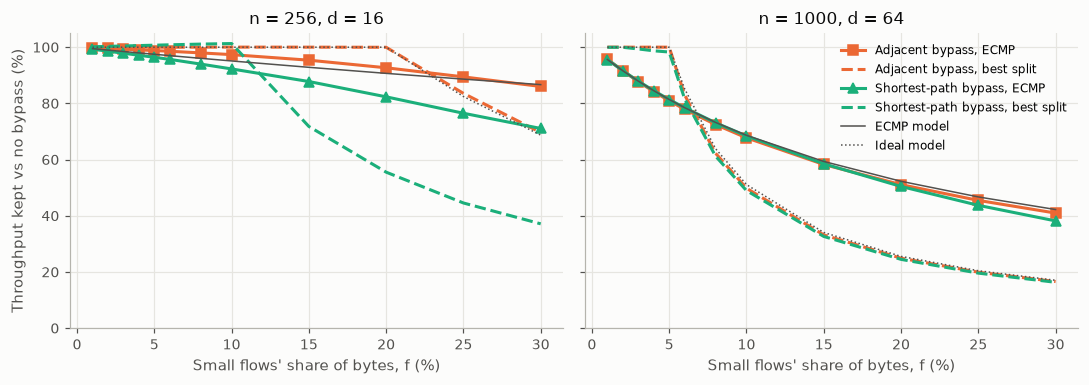

In [3]:
if scales:
    figure, axes = plt.subplots(1, len(scales), figsize=(5 * len(scales), 3.6), sharey=True)
    for axis, (nodes, degree) in zip(np.atleast_1d(axes), scales):
        rows = checks[(checks["nodes"] == nodes) & (checks["degree"] == degree)]
        mean = rows.groupby(["mode", "share"])[["ecmp_kept", "lp_kept", "model_ecmp_kept", "model_ideal_kept"]].mean()
        for mode in ["adjacent", "shortest"]:
            if mode not in mean.index.get_level_values("mode"):
                continue
            data = mean.xs(mode, level="mode")
            color = common.MODE_COLORS[mode]
            axis.plot(data.index * 100, data["ecmp_kept"] * 100, color=color, marker=common.MODE_MARKERS[mode], label=f"{common.MODE_NAMES[mode]}, ECMP")
            axis.plot(data.index * 100, data["lp_kept"] * 100, color=color, linestyle="--", label=f"{common.MODE_NAMES[mode]}, best split")
        data = mean.xs("adjacent", level="mode") if "adjacent" in mean.index.get_level_values("mode") else mean.groupby("share").mean()
        axis.plot(data.index * 100, data["model_ecmp_kept"] * 100, color="#52514e", linewidth=1, label="ECMP model")
        axis.plot(data.index * 100, data["model_ideal_kept"] * 100, color="#52514e", linewidth=1, linestyle=":", label="Ideal model")
        axis.set(title=f"n = {nodes}, d = {degree}", xlabel="Small flows' share of bytes, f (%)", ylim=(0, 105))
    np.atleast_1d(axes)[0].set_ylabel("Throughput kept vs no bypass (%)")
    np.atleast_1d(axes)[-1].legend(fontsize=8)
    figure.tight_layout()

## 2. ns-3 under permutation traffic

Every router's hosts send only to their partner router, the same pairs as matching 0 of the flow-level check for that seed. Each pair's throughput is the mean goodput of its large flows, and `kept` is that over the same pair's goodput with no bypass, on the same flows.

Pairs are grouped as the models group them: adjacent pairs and 2-hop pairs with one shortest path have *c* = 1 and should lose the most once the bypass loads their single path.

In [4]:
baseline = common.load_runs(common.BASELINE_EXPERIMENT)
bypass = common.load_runs(common.BYPASS_EXPERIMENT)
permutation = [r for r in baseline + bypass if r.options.get("pattern") == "permutation"]
complete = {(r.setting, r.seed) for r in permutation if r.bypass == "none"}
for mode in {r.bypass for r in permutation if r.bypass != "none"}:
    complete &= {(r.setting, r.seed) for r in permutation if r.bypass == mode}
if not any(r.bypass != "none" for r in permutation):
    complete = set()
runs = [r for r in permutation if (r.setting, r.seed) in complete]
ready = bool(runs) and not pair_loads.empty
if ready:
    modes = [m for m in common.MODES if m in {r.bypass for r in runs}]
    flows = common.load_flows(runs)
    print(f"Comparing {len(complete)} setting and seed pairs, modes {modes}")
else:
    print(f"Nothing to compare yet: {len(permutation)} finished permutation runs, "
          f"{'with' if not pair_loads.empty else 'without'} a flow-level check in this batch.")

Comparing 36 setting and seed pairs, modes ['none', 'adjacent', 'shortest']


In [5]:
def pair_kind(distance, c):
    if distance == 1:
        return "adjacent (c = 1)"
    if distance == 2:
        return "2 hops, c = 1" if c == 1 else ("2 hops, c = 2" if c == 2 else "2 hops, c ≥ 3")
    return "3+ hops"

KINDS = ["adjacent (c = 1)", "2 hops, c = 1", "2 hops, c = 2", "2 hops, c ≥ 3", "3+ hops"]

if ready:
    nodes, degree = int(runs[0].options["nodes"]), int(runs[0].options["degree"])
    keys = [*common.SETTINGS, "seed", "source_router", "destination_router"]
    large = flows[flows["class"] == "large"]
    per_pair = large.groupby(keys + ["bypass"])["goodput_gbps"].mean().unstack("bypass")
    for mode in modes:
        if mode != "none":
            per_pair[f"kept_{mode}"] = per_pair[mode] / per_pair["none"]
    per_pair = per_pair.reset_index()

    # Each pair's distance and c, from the flow-level check's matching 0 for the same seed.
    shape = pair_loads[(pair_loads["nodes"] == nodes) & (pair_loads["degree"] == degree) & (pair_loads["matching"] == 0) & (pair_loads["mode"] == "none")]
    shape = shape.rename(columns={"source": "source_router", "destination": "destination_router"})[["seed", "source_router", "destination_router", "distance", "c"]]
    per_pair = per_pair.merge(shape, on=["seed", "source_router", "destination_router"], how="left")
    missing = per_pair["c"].isna().sum()
    print(f"{len(per_pair)} pair-settings; {missing} not in the flow-level check's matching 0" + (" (check the seeds and network size)" if missing else ""))
    per_pair = per_pair.dropna(subset=["c"])
    per_pair["kind"] = pd.Categorical([pair_kind(d, c) for d, c in zip(per_pair["distance"], per_pair["c"])], categories=KINDS, ordered=True)
    kept = [f"kept_{m}" for m in modes if m != "none"]
    summary = per_pair.groupby([*common.SETTINGS, "kind"], observed=True)[kept].agg(["mean", "min"])
    summary.columns = [f"{column}_{stat}" for column, stat in summary.columns]
    display(summary.join(per_pair.groupby([*common.SETTINGS, "kind"], observed=True).size().rename("pairs")))

9216 pair-settings; 0 not in the flow-level check's matching 0


kept_adjacent_mean  kept_adjacent_min  \
share load  kind                                                      
0.083 0.100 adjacent (c = 1)               1.000              0.986   
            2 hops, c = 1                  1.001              0.982   
            2 hops, c = 2                  1.000              0.985   
            2 hops, c ≥ 3                  1.000              0.989   
            3+ hops                        1.000              0.948   
      0.200 adjacent (c = 1)               0.995              0.958   
            2 hops, c = 1                  1.001              0.955   
            2 hops, c = 2                  1.001              0.962   
            2 hops, c ≥ 3                  1.002              0.991   
            3+ hops                        1.000              0.971   
      0.300 adjacent (c = 1)               0.983              0.933   
            2 hops, c = 1                  1.002              0.932   
            2 hops, c = 2                  1.001              0.966   
            2 hops, c ≥ 3                  1.000              0.961   
            3+ hops                        1.001              0.963   
      0.400 adjacent (c = 1)               0.976              0.918   
            2 hops, c = 1                  1.001              0.945   
            2 hops, c = 2                  1.002              0.943   
            2 hops, c ≥ 3                  0.998              0.955   
            3+ hops                        1.004              0.956   
0.200 0.100 adjacent (c = 1)               0.996              0.970   
            2 hops, c = 1                  1.000              0.922   
            2 hops, c = 2                  1.000              0.976   
            2 hops, c ≥ 3                  0.999              0.989   
            3+ hops                        1.001              0.979   
      0.200 adjacent (c = 1)               0.983              0.921   
            2 hops, c = 1                  1.002              0.964   
            2 hops, c = 2                  1.002              0.968   
            2 hops, c ≥ 3                  1.003              0.956   
            3+ hops                        1.001              0.950   
      0.300 adjacent (c = 1)               0.960              0.869   
            2 hops, c = 1                  1.001              0.939   
            2 hops, c = 2                  1.003              0.951   
            2 hops, c ≥ 3                  1.007              0.973   
            3+ hops                        1.002              0.952   
      0.400 adjacent (c = 1)               0.931              0.818   
            2 hops, c = 1                  1.003              0.930   
            2 hops, c = 2                  1.001              0.927   
            2 hops, c ≥ 3                  1.002              0.939   
            3+ hops                        1.005              0.938   
0.300 0.100 adjacent (c = 1)               0.993              0.963   
            2 hops, c = 1                  1.001              0.978   
            2 hops, c = 2                  1.002              0.984   
            2 hops, c ≥ 3                  1.002              0.991   
            3+ hops                        1.001              0.978   
      0.200 adjacent (c = 1)               0.976              0.908   
            2 hops, c = 1                  1.001              0.906   
            2 hops, c = 2                  1.002              0.967   
            2 hops, c ≥ 3                  1.005              0.973   
            3+ hops                        1.002              0.935   
      0.300 adjacent (c = 1)               0.930              0.791   
            2 hops, c = 1                  1.000              0.935   
            2 hops, c = 2                  1.005              0.961   
            2 hops, c ≥ 3                  1.004              0.957   
            3+ hops                        1.002      

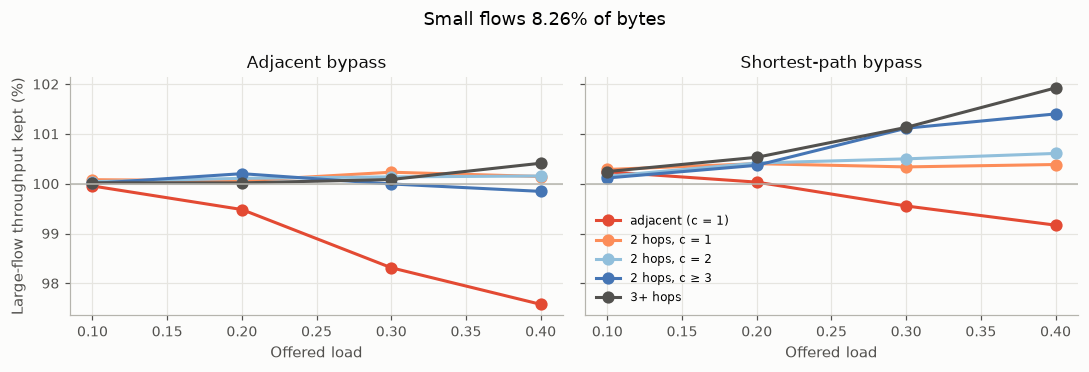

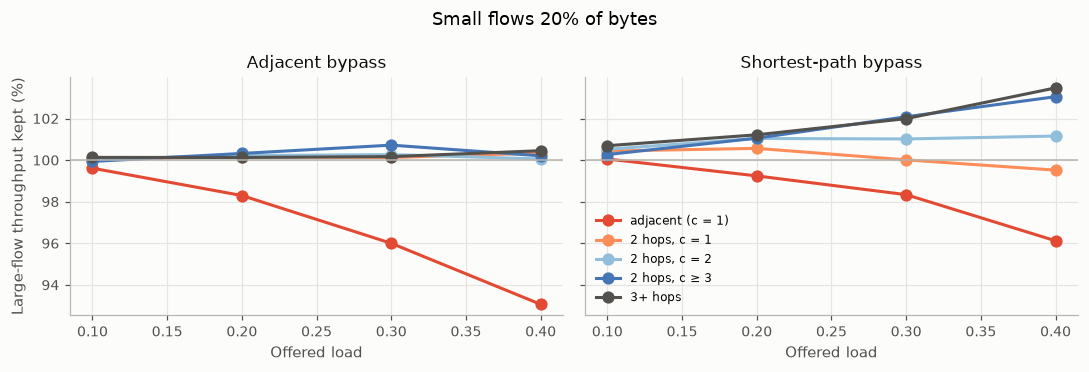

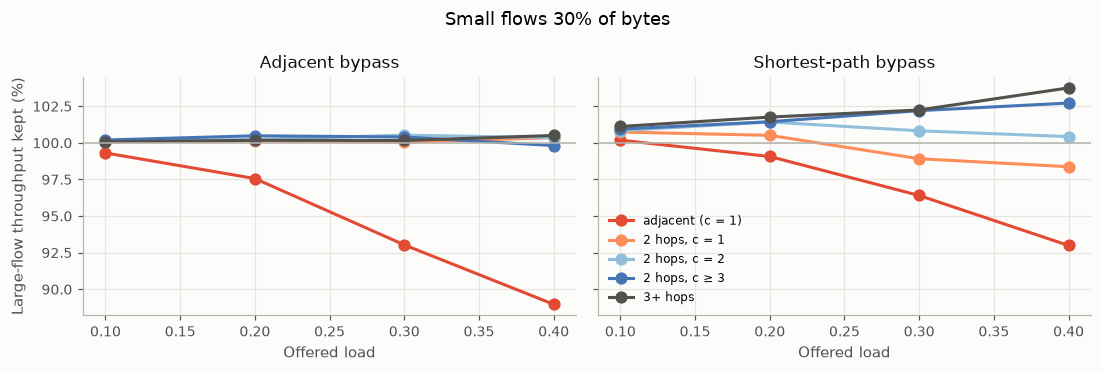

In [6]:
if ready:
    for title, rows in common.panels(per_pair):
        figure, axes = plt.subplots(1, len(kept), figsize=(5 * len(kept), 3.4), sharey=True)
        for axis, column in zip(np.atleast_1d(axes), kept):
            mean = rows.groupby(["kind", common.SETTING], observed=True)[column].mean()
            for i, kind in enumerate(k for k in KINDS if k in mean.index.get_level_values("kind")):
                data = mean.xs(kind, level="kind")
                axis.plot(data.index, data * 100, marker="o", color=["#e34a33", "#fc8d59", "#91bfdb", "#4575b4", "#52514e"][KINDS.index(kind)], label=kind)
            axis.axhline(100, color="#b5b4ad", linewidth=1)
            axis.set(title=common.MODE_NAMES[column.removeprefix("kept_")])
            common.label_setting_axis(axis)
        np.atleast_1d(axes)[0].set_ylabel("Large-flow throughput kept (%)")
        np.atleast_1d(axes)[-1].legend(fontsize=8)
        if title:
            figure.suptitle(title)
        figure.tight_layout()

### Does ns-3 slow down the pairs the flow-level check says are loaded?

For each pair, the flow-level check gives the busiest link its large flows cross under ECMP, at the nearest share it computed (matching 0, same seed). If the ECMP model describes ns-3, pairs whose links it says are busier should get less throughput. `spearman` is the rank correlation between the two at the highest load; negative means they agree.

In [7]:
if ready:
    top = per_pair[common.SETTING].max()
    predicted = pair_loads[(pair_loads["nodes"] == nodes) & (pair_loads["degree"] == degree) & (pair_loads["matching"] == 0)]
    predicted = predicted.rename(columns={"source": "source_router", "destination": "destination_router"})
    shares = sorted(predicted["share"].unique())
    rows = []
    for (share, mode), group in per_pair[per_pair[common.SETTING] == top].assign(share=lambda f: f.get("share", 0)).melt(
        id_vars=["share", "seed", "source_router", "destination_router", "kind"], value_vars=modes, var_name="mode", value_name="goodput"
    ).groupby(["share", "mode"]):
        nearest = 0 if mode == "none" else min((s for s in shares if s > 0), key=lambda s: abs(s - share))
        model = predicted[(predicted["share"] == nearest) & (predicted["mode"] == mode)][["seed", "source_router", "destination_router", "large_bottleneck"]]
        joined = group.merge(model, on=["seed", "source_router", "destination_router"])
        rows.append({"share": share, "mode": mode, "model_share": nearest, "pairs": len(joined),
                     # Spearman: the correlation of the ranks, without needing scipy.
                     "spearman": joined["goodput"].rank().corr(joined["large_bottleneck"].rank())})
    display(pd.DataFrame(rows).set_index(["share", "mode"]))

model_share  pairs  spearman
share mode                                  
0.083 adjacent        0.080    768    -0.230
      none            0.000    768    -0.230
      shortest        0.080    768    -0.268
0.200 adjacent        0.200    768    -0.254
      none            0.000    768    -0.235
      shortest        0.200    768    -0.279
0.300 adjacent        0.300    768    -0.287
      none            0.000    768    -0.225
      shortest        0.300    768    -0.255